# 2. Depth From Connections

> **Overview.** An LTU reads only LTUs below it, so a depth-2 LTU that learns a feature that depth-2 LTUs need strands
> it. With notebook 1's pruning, can each LTU simply move down to just above the deepest LTU it reads?

**Setup.** Notebook 1's method and budget, with LTUs at two depths. Half of the 16 target LTUs are at depth 2, each
reading 5 inputs and 5 depth-1 target LTUs. A new LTU starts one depth below its parent, depth 2 if its parent is an
output, and reads inputs and LTUs of lower depth. Every 10k steps, after pruning, each LTU moves down to one depth
above the deepest LTU it reads (depth 1 if it reads only inputs), or never. Output noise of std 0.1 or 1. 5 seeds; 1M
steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_DEPTHS = 2                         # depths of target LTUs, and the most depths of the learner's LTUs
N_TARGETS = 16                       # target LTUs, the first half at depth 1 and the second at depth 2
N_SOURCES = 10                       # sources each target LTU reads, drawn at random: 10 inputs at depth 1; 5 inputs
                                     # and 5 depth-1 target LTUs at depth 2
N_OUTPUTS = 10
OUTPUT_FAN_IN = 4                    # target LTUs each output reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # observation noise on each output: the lowest RMSE possible
BUDGET = 2 * N_TARGETS * N_SOURCES   # connections from the inputs and LTUs to the LTUs: room for 2 LTUs like each
                                     # target LTU

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
SLOTS = 48                           # most LTUs at once
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects a source whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads up to this many sources
REPLACED = 4                         # LTUs removed at each search step, those with the smallest sum of |outgoing weights|

# --- Experiment ---
NUM_STEPS = 1_000_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps, each just after a pruning

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS + N_TARGETS): the target LTUs' weights over [inputs, target LTUs]
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the outputs' weights, +-1/2 on the target LTUs they read


def make_target(key):
    # Each depth-1 target LTU reads N_SOURCES inputs, each depth-2 one half as many inputs and as many depth-1 target
    # LTUs, and each output OUTPUT_FAN_IN target LTUs, all drawn at random, with random +-1 weights (the outputs' scaled
    # to unit variance).
    read_key, lower_key, w_key, out_key, out_w_key = jax.random.split(key, 5)
    half = N_TARGETS // 2
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    inputs = pick(read_key, (N_TARGETS, N_INPUTS),
                  jnp.where(jnp.arange(N_TARGETS) < half, N_SOURCES, N_SOURCES // 2)[:, None])
    lower = jnp.zeros((N_TARGETS, N_TARGETS), bool).at[half:, :half].set(pick(lower_key, (half, half), N_SOURCES // 2))
    w = (jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS + N_TARGETS), dtype=float)
         * jnp.concatenate([inputs, lower], 1))
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN))
    return Target(w, out)


def sample(target, noise_std, key):
    # One input and its targets, with N(0, noise_std^2) noise.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    s = jnp.zeros(N_TARGETS)
    for _ in range(N_DEPTHS):   # depth by depth
        s = jnp.where(target.w @ jnp.concatenate([x, s]) > 0, 1.0, -1.0)
    return x, target.out @ s + noise_std * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

Notebook 1's learner, with depths: an LTU reads inputs and LTUs of lower depth, and its parent may be an LTU, which
reads it from its creation; `move` lowers each LTU to just above the deepest LTU it reads.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (SLOTS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, LTUs, 1 (the bias)], of which each reads those in `reads`;
    # w['output'] is the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (SLOTS, N_INPUTS + SLOTS + 1), 'output': (N_OUTPUTS, N_INPUTS + SLOTS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    depth: jax.Array            # (SLOTS,): each LTU's depth, 0 for an empty slot
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS + SLOTS, SLOTS): each LTU's shadow weight, +-1 on one of [outputs, LTUs] (its
                                # parent), 0 elsewhere
    candidates: jax.Array       # (SLOTS, N_INPUTS + SLOTS): each LTU's sums of dL/dz * source since its last new
                                # connection


def may_read(depth):
    # Shaped like w['hidden']: every input and the bias, and the LTUs of lower depth.
    lower = (depth[None] > 0) & (depth[None] < depth[:, None])
    return jnp.concatenate([jnp.ones((SLOTS, N_INPUTS), bool), lower, jnp.ones((SLOTS, 1), bool)], 1)


def used(net):
    # The LTUs' connections from the inputs and LTUs, which count against the budget.
    return net.reads[:, :-1].sum()


def clear(net, slots):
    # Empties `slots`: their LTUs' connections in and out are cut, with their weights, Autostep state and gradient
    # sums, and their shadow weights, and those on them, dropped.
    col = jnp.concatenate([jnp.zeros(N_INPUTS, bool), slots, jnp.zeros(1, bool)])
    where = {'hidden': slots[:, None] | col[None], 'output': col[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    opt = net.opt._replace(beta=reset(net.opt.beta, jax.tree.map(lambda z: z + net.opt.init_beta, zeros)),
                           h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(slots, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    parents = jnp.concatenate([jnp.zeros(N_OUTPUTS, bool), slots])
    return net._replace(w=reset(net.w, zeros), reads=net.reads & ~where['hidden'], depth=jnp.where(slots, 0, net.depth),
                        opt=opt, stats=stats, shadow=net.shadow * ~parents[:, None] * ~slots[None],
                        candidates=jnp.where(where['hidden'][:, :-1], 0.0, net.candidates))


def rewire(net, key, slots, random):
    # Each of the empty `slots` gets a new LTU. Its parent is a random unit of a random layer above depth 1, the outputs
    # (layer N_DEPTHS + 1) included; its shadow weight on it is +1 or -1 by slot, and its depth one below its parent's.
    # It reads the bias and up to FAN_IN sources it may read, drawn without replacement with probability proportional
    # to the square of its parent's weight on each (uniformly if random) (Gumbel top-k), with LeCun uniform weights
    # taking the signs of its shadow weight times its parent's weights (random signs if random), at step-size
    # FAST_STEP_SIZE. A parent LTU reads its new LTU, from weight 0 at step-size FAST_STEP_SIZE.
    parent_key, draw_key, w_key = jax.random.split(key, 3)
    layer = jnp.concatenate([jnp.full(N_OUTPUTS, N_DEPTHS + 1), jnp.where(net.depth > 1, net.depth, 0)])
    size = (layer[None] == layer[:, None]).sum(1)
    scores = jnp.where(layer > 0, -jnp.log(size), -jnp.inf) + jax.random.gumbel(parent_key, (SLOTS, N_OUTPUTS + SLOTS))
    parent = jnp.argmax(scores, 1)
    sign = jnp.where(jnp.arange(SLOTS) % 2 == 0, 1.0, -1.0)
    shadow = jnp.where(slots, (jnp.arange(N_OUTPUTS + SLOTS)[:, None] == parent) * sign, net.shadow)
    depth = jnp.where(slots, layer[parent] - 1, net.depth)
    parent_w = (shadow.T @ jnp.concatenate([net.w['output'], net.w['hidden'] * net.reads]))[:, :-1]
    weights = jnp.where(may_read(depth)[:, :-1], jnp.where(random, 1.0, parent_w), 0.0)
    fan_in = jnp.minimum(FAN_IN, (weights != 0).sum(1, keepdims=True))
    scores = jnp.log(weights ** 2) + jax.random.gumbel(draw_key, weights.shape)
    sources = (jnp.argsort(jnp.argsort(-scores)) < fan_in) & slots[:, None]
    w = jax.random.uniform(w_key, weights.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / jnp.maximum(fan_in, 1))
    w = jnp.where(random, w, jnp.abs(w) * jnp.sign(parent_w))
    link = (shadow[N_OUTPUTS:] != 0) & slots[None]          # each parent LTU's connection from its new LTU
    new = jnp.concatenate([sources.at[:, N_INPUTS:].set(sources[:, N_INPUTS:] | link), jnp.zeros((SLOTS, 1), bool)], 1)
    hidden = jnp.where(sources, w, net.w['hidden'][:, :-1])
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.append(hidden, net.w['hidden'][:, -1:], axis=1)},
                        reads=net.reads | new | jnp.zeros_like(net.reads).at[:, -1].set(slots),
                        depth=depth, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}), shadow=shadow)


def init_net(key, target, wired):
    # If wired, 2 LTUs wired like each target LTU in turn (the reference): at its depth, reading its inputs, the first
    # LTU wired like each target LTU it reads, and the bias, with LeCun uniform weights at step-size FAST_STEP_SIZE;
    # their shadow weights +1 and -1, on a random output that reads that target LTU. Otherwise as many new LTUs as the
    # budget has room for at FAN_IN inputs each, reading random inputs with random signs (their parents, outputs, have
    # no weights yet). Every other weight 0.
    w_key, out_key, wire_key = jax.random.split(key, 3)
    slot = jnp.arange(SLOTS)
    on = wired & (slot < 2 * N_TARGETS)
    assigned = slot // 2 % N_TARGETS
    target_reads = target.w[assigned] != 0
    lower = target_reads[:, N_INPUTS:][:, assigned] & ((slot % 2 == 0) & on)[None]
    reads = jnp.concatenate([target_reads[:, :N_INPUTS], lower, jnp.ones((SLOTS, 1), bool)], 1) & on[:, None]
    depth = jnp.where(on, 1 + (assigned >= N_TARGETS // 2), 0)
    readers = target.out[:, assigned] != 0
    readers = readers | ~readers.any(0)
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS + SLOTS)[:, None] == parent) * jnp.where(slot % 2 == 0, 1.0, -1.0) * on
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / N_SOURCES) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + SLOTS + 1))}
    opt = OPTIMIZER.init(w)
    beta = jnp.where(reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), opt.beta['hidden'])
    stats = Stats(jnp.full(SLOTS, 0.5), jnp.zeros(SLOTS), jnp.zeros(SLOTS))
    net = Net(w, reads, depth, opt._replace(beta={**opt.beta, 'hidden': beta}), stats, shadow,
              jnp.zeros((SLOTS, N_INPUTS + SLOTS)))
    return rewire(net, wire_key, ~wired & (slot < BUDGET // FAN_IN), True)


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, the LTUs computed depth by
    # depth, each LTU's shadow weight standing in for its weight to its parent in the backward pass while the real one
    # is smaller than 1 in magnitude. Returns the new network and its prediction for this sample, made before learning
    # from it, and adds dL/dz * source to each LTU's gradient sums. `probe` is zero; its gradients are the error
    # arriving at each LTU and dL/dz.

    def loss_fn(w, probe):
        hidden = w['hidden'] * net.reads
        unit_w = jnp.concatenate([w['output'], hidden])[:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w))
        a = jnp.zeros(SLOTS)
        for d in range(1, N_DEPTHS + 1):
            through = back[N_OUTPUTS:] @ a
            z = (hidden @ jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)])) + through
                 - jax.lax.stop_gradient(through))
            b = ltu(z + probe[1])
            mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
            h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
            a = jnp.where(net.depth == d, h + probe[0], a)
        source = jnp.concatenate([x, a, jnp.ones(1)])
        through = back[:N_OUTPUTS] @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + through - jax.lax.stop_gradient(through)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean,
                                                       jax.lax.stop_gradient(prediction))

    (loss, (source, h, mean, prediction)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(SLOTS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': source[None] * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * source[:-1]), prediction


def grow(net):
    # Each LTU whose largest gradient sum, over the sources it may read but does not, is more than GROW_Z times their
    # root mean square connects that source, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums, while
    # the budget has room (the lowest slots first).
    unread = may_read(net.depth)[:, :-1] & ~net.reads[:, :-1]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & (net.depth > 0)
    grows = grows & (jnp.cumsum(grows) <= BUDGET - used(net))
    new = (jnp.arange(N_INPUTS + SLOTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def prune(net, signs):
    # Each LTU stops reading every source whose weight's sign differs from `signs`, its sign at the last pruning (0 for
    # sources read since); the bias stays. The cut connections' weights and Autostep state are reset.
    w = net.w['hidden'][:, :-1]
    cut = jnp.zeros_like(net.reads).at[:, :-1].set(net.reads[:, :-1] & (signs != 0) & (jnp.sign(w) != signs))
    zero = lambda t: {**t, 'hidden': jnp.where(cut, 0.0, t['hidden'])}
    beta = jnp.where(cut, net.opt.init_beta, net.opt.beta['hidden'])
    opt = net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v))
    return net._replace(w=zero(net.w), reads=net.reads & ~cut, opt=opt)


def move(net):
    # Each LTU moves down to one depth above the deepest LTU it reads (depth 1 if it reads only inputs).
    deepest = jnp.max(jnp.where(net.reads[:, N_INPUTS:-1], net.depth[None], 0), 1)
    return net._replace(depth=jnp.where(net.depth > 0, deepest + 1, 0))


def search(net, key):
    # The REPLACED LTUs with the smallest sum of |outgoing weights| are removed; then new LTUs fill empty slots while
    # the budget has room for their connections. Returns the network and the slots filled.
    strength = jnp.abs(jnp.concatenate([net.w['output'], net.w['hidden'] * net.reads])[:, N_INPUTS:-1]).sum(0)
    units = net.depth > 0
    removed = units & (jnp.argsort(jnp.argsort(jnp.where(units, strength, jnp.inf))) < REPLACED)
    net = clear(net, removed)
    empty = net.depth == 0
    filled = rewire(net, key, empty, False)
    cost = filled.reads[:, :-1].sum(1) + filled.reads[:, N_INPUTS:-1].sum(0)   # its sources and its parent's link
    new = empty & (jnp.cumsum(jnp.where(empty, cost, 0)) <= BUDGET - used(net))
    return clear(filled, empty & ~new), new

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, noise_std, wired, moves):
    # NUM_STEPS online network-Autostep steps on samples from `target` with noise_std. Unless wired, each LTU grows
    # every WINDOW steps, and every PERIOD steps the LTUs are pruned, moved down (if moves), then searched, and the
    # signs of the weights recorded (0 for the new LTUs'). Returns each window's mean squared error and the number of
    # LTUs at its end.
    def window(carry, inputs):
        net, signs = carry
        index, key = inputs
        search_key, key = jax.random.split(key)

        def step(net, key):
            x, y = sample(target, noise_std, key)
            net, prediction = learn(net, x, y)
            return net, jnp.mean((prediction - y) ** 2)

        net, mse = jax.lax.scan(step, net, jax.random.split(key, WINDOW))
        net = pick(~wired, grow(net), net)
        due = ~wired & ((index + 1) * WINDOW % PERIOD == 0)
        net = pick(due, prune(net, signs), net)
        net = pick(due & moves, move(net), net)
        searched, new = search(net, search_key)
        net = pick(due, searched, net)
        signs = jnp.where(due, jnp.sign(net.w['hidden'][:, :-1]) * net.reads[:, :-1] * ~new[:, None], signs)
        return (net, signs), (mse.mean(), (net.depth > 0).sum())

    n = NUM_STEPS // WINDOW
    start = (net, jnp.zeros_like(net.w['hidden'][:, :-1]))
    return jax.lax.scan(window, start, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (wired, moves) of configs at every noise std of NOISE_STDS and on N_SEEDS seeds, vmapped together; seed s
    # gives every run the same target network and samples. Returns {(config, noise std): the RMSE of each window,
    # shaped (seed, window)} and the most LTUs any run held at once.
    runs = [(c, n) for c in configs for n in NOISE_STDS]
    noise, wired, moves, seed = (jnp.array(v) for v in zip(*[(n, *c, s) for c, n in runs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(init_net)(keys(0), targets, wired)
    mse, ltus = jax.jit(jax.vmap(train))(nets, keys(1), targets, noise, wired, moves)
    return dict(zip(runs, np.sqrt(np.asarray(mse)).reshape(len(runs), N_SEEDS, -1))), int(ltus.max())

## Runs

In [6]:
MOVED, STAYED, REFERENCE = (False, True), (False, False), (True, False)
started = perf_counter()
rmse, most = run([MOVED, STAYED, REFERENCE])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s; at most {most} of {SLOTS} LTUs at once')

30 runs in 121s; at most 42 of 48 LTUs at once


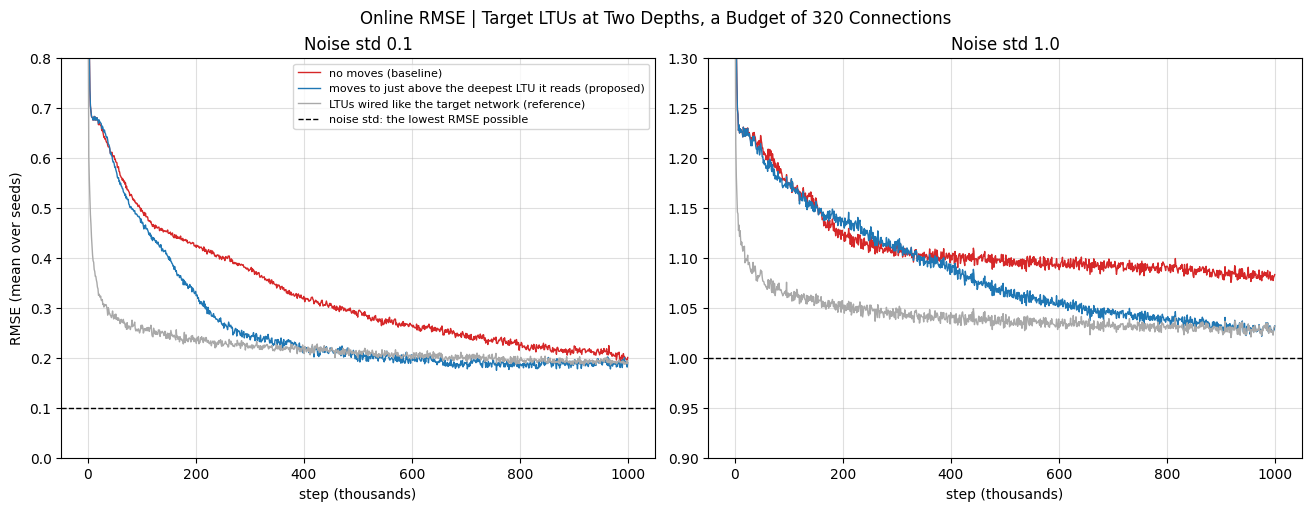

noise 0.1, RMSE over the last 100k steps: no moves 0.210, moves to just above the deepest LTU it reads 0.189, LTUs wired like the target network 0.193
noise 1.0, RMSE over the last 100k steps: no moves 1.083, moves to just above the deepest LTU it reads 1.030, LTUs wired like the target network 1.028


In [7]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
CURVES = [('no moves (baseline)', STAYED, 'tab:red'),
          ('moves to just above the deepest LTU it reads (proposed)', MOVED, 'tab:blue'),
          ('LTUs wired like the target network (reference)', REFERENCE, 'darkgray')]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, noise, ylim in zip(axes, NOISE_STDS, [(0, 0.8), (0.9, 1.3)]):
    for label, config, color in CURVES:
        ax.plot(STEPS / 1000, rmse[config, noise].mean(0), color=color, lw=1, label=label)
    ax.axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
    ax.set(title=f'Noise std {noise}', xlabel='step (thousands)', ylim=ylim)
    ax.grid(alpha=0.4)
axes[0].legend(fontsize=8)
axes[0].set_ylabel('RMSE (mean over seeds)')
fig.suptitle(f'Online RMSE | Target LTUs at Two Depths, a Budget of {BUDGET} Connections')
plt.show()

last = 100_000 // WINDOW
for noise in NOISE_STDS:
    print(f'noise {noise}, RMSE over the last 100k steps: '
          + ', '.join(f'{label.split(" (")[0]} {rmse[config, noise][:, -last:].mean():.3f}' for label, config, _ in CURVES))

## Results

With moves, the method ends level with LTUs wired like the target network at both noise levels: by about 350k steps
at noise 0.1 and 1M at noise 1. Without moves, some depth-2 LTUs read only inputs, holding features no depth-2 LTU can
read (Details), and the method learns much more slowly: at 1M steps it is still above the reference at noise 0.1
(RMSE 0.21 against 0.19), and stalls at noise 1 (1.08 against 1.03, with the noise floor at 1).

## Details

**Target.** As in notebook 1, but the second 8 target LTUs each read 5 inputs and 5 of the first 8 target LTUs instead
of 10 inputs, and the outputs read 4 of all 16.

**Depths.** A new LTU's parent is a random unit of a random layer above depth 1, the outputs included. The new LTU
starts one depth below its parent and reads up to 20 sources it may read, drawn by its parent's weights. A parent LTU
reads its new LTU from weight 0, and later prunes that connection like any other. The first LTUs' parents are outputs,
so they start at depth 2. The budget counts the connections from LTUs as well as from inputs.

**Stranded features.** Without moves, about 6 of the 17 depth-2 LTUs read only inputs at 600k steps with noise 0.1
(checked separately, 5 seeds).

**The swap.** Moving an LTU down a depth when less than 10% of its input |weights| are on the depth below, the
trigger of the swap in `../step_by_step/5_several_layers.ipynb`, and cutting those connections, does the same as the
move: RMSE 0.18 against 0.19 at noise 0.1, and 1.04 against 1.03 at noise 1 (checked separately, 5 seeds).